# Programming in Python II - Final Coding Project

Author:

Student ID:

Save this file under a file name in the format k+matriculation_number.ipynb, e.g. *k1234567.ipynb*. Remember that for final submission all code cells must run without errors and all cells have to be evaluated.

The code cells are a basic scaffold - you can of course add new code cells if necessary. However, stick to the overall structure of the template to facilitate grading. Ensure to comment your code and structure it reasonably.

In [1]:
import random
import numpy as np
import torch

seed = 42

random.seed(seed)
np.random.seed(seed)
torch.manual_seed(seed)

if torch.cuda.is_available():
    torch.cuda.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

In [ ]:
# This is just a minimum setup for reproducibility. Add more libraries as required.

import numpy as np
import torch
import matplotlib.pyplot as plt
import os

# Setting device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
if torch.backends.mps.is_available():
    device = torch.device("mps")

# Set random seeds for reproducibility
np.random.seed(42)
torch.manual_seed(42)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(42)
    

cuda


In [3]:
# checking successful setup
print(f"Using device: {device}")

Using device: cuda


In [4]:
# For visualization in Jupyter notebooks
%matplotlib inline

In [5]:
# Set working directory to the project folder
# os.chdir("path/to/project")  # only needed if the notebook is not started from the project folder
print(f"Current working directory: {os.getcwd()}")


In [6]:
# creating folder 'assets' if necessary
os.makedirs("assets", exist_ok=True)

## Data Handling and Pre-Processing

In [7]:
# your code goes here (preprocess function)
import pandas as pd 


def preprocess(data_folder: str) -> tuple[pd.DataFrame, dict]:
    dataset_dir = data_folder

    classes = sorted([
    d for d in os.listdir(dataset_dir)
    if os.path.isdir(os.path.join(dataset_dir, d))
    
])
    #print(classes)
    label_map = {name: idx for idx, name in enumerate(classes)}

    #print(label_map)
    

    rows = []


    for label_name in classes:
        folder_path = os.path.join(dataset_dir, label_name)

        for file in os.listdir(folder_path):
            
            rows.append({
            "image_folder": folder_path,
            "image_path": os.path.join(folder_path, file),
            "label": label_map[label_name]})
            

    df = pd.DataFrame(rows)

    #print(df.head())
    return (df,label_map)


df, classes = preprocess('data')
rev_classes = {v: k for k, v in classes.items()}


In [8]:
# your code goes here (preprocess function)
import pandas as pd 


def preprocess(data_folder: str) -> tuple[pd.DataFrame, dict]:
    dataset_dir = data_folder

    classes = sorted([
    d for d in os.listdir(dataset_dir)
    if os.path.isdir(os.path.join(dataset_dir, d))
    
])
    #print(classes)
    label_map = {name: idx for idx, name in enumerate(classes)}

    #print(label_map)
    

    rows = []


    for label_name in classes:
        folder_path = os.path.join(dataset_dir, label_name)

        for file in os.listdir(folder_path):
            
            rows.append({
            "image_folder": folder_path,
            "image_path": os.path.join(folder_path, file),
            "label": label_map[label_name]})
            

    df = pd.DataFrame(rows)

    #print(df.head())
    return (df,label_map)


df, classes = preprocess('data')
rev_classes = {v: k for k, v in classes.items()}


In [9]:
# checking successful dataframe loading

# uncomment after preprocessing the dataset and adapt the variable name
print(f"Length of dataset: {len(df)}") # Should be 10000


#rev_classes[int(df.iloc[1]['label'])]


Length of dataset: 10000


In [10]:
# your code goes here (splitting train/validation datasets)


import pandas as pd

def manual_split(df: pd.DataFrame, train_ratio: float = 0.8):
    train_parts = []
    test_parts = []

    for label in df["label"].unique():
        class_df = df[df["label"] == label]

        split_idx = int(len(class_df) * train_ratio)

        train_parts.append(class_df.iloc[:split_idx])
        test_parts.append(class_df.iloc[split_idx:])

    train_df = pd.concat(train_parts)
    test_df = pd.concat(test_parts)

    return train_df, test_df

from sklearn.model_selection import train_test_split

def sklearn_split(df: pd.DataFrame, test_size: float = 0.2, seed: int = 42):
    train_df, test_df = train_test_split(
        df,
        test_size=test_size,
        random_state=seed,
        stratify=df["label"]
    )

    return train_df, test_df

train_df, test_df = manual_split(df)
#train_df, test_df = sklearn_split(df)


## Exploratory Data Analysis (EDA)

In [11]:
asset_path = os.path.join(os.getcwd(), "assets") #assets path 

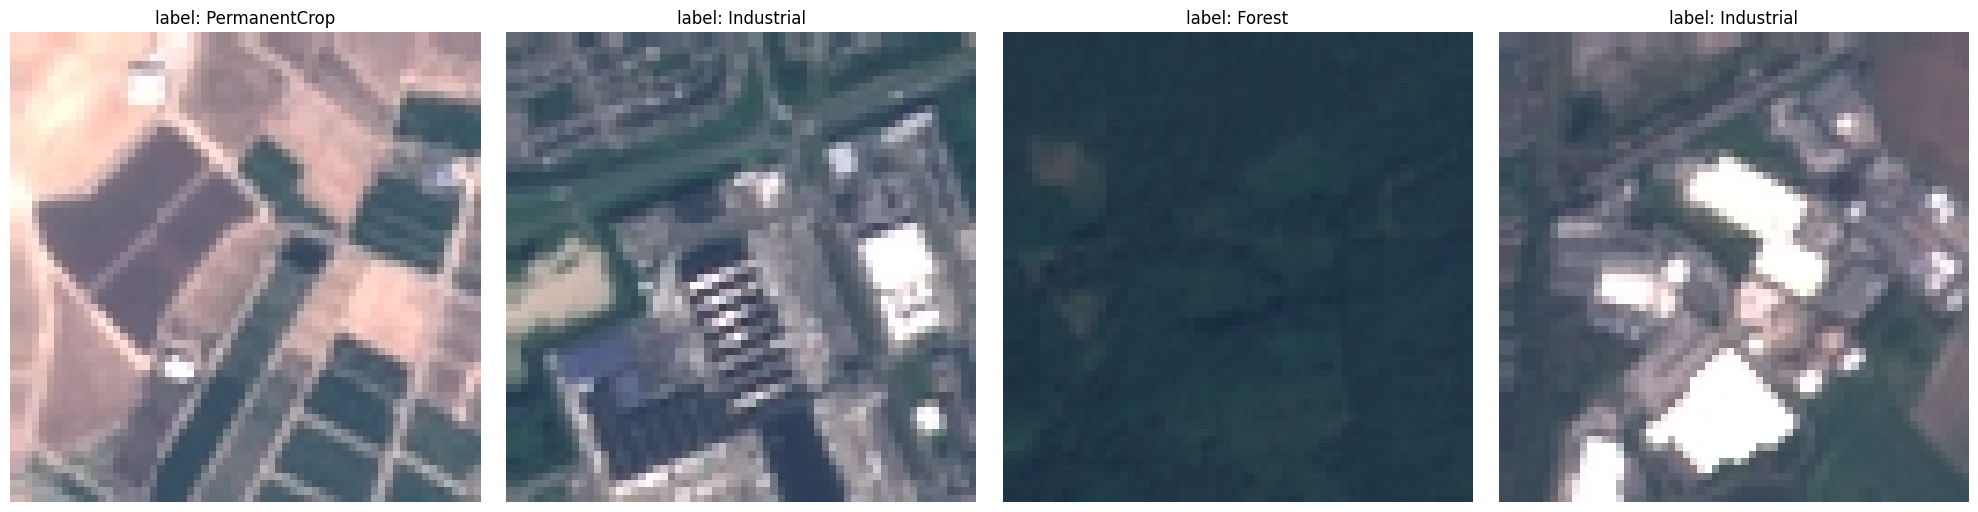

In [12]:
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import numpy as np

def show_samples(df, num_samples=5):
    sample_indices = np.random.choice(df.index, min(num_samples, len(df)), replace=False)

    plt.figure(figsize=(20, 5))

    for i, idx in enumerate(sample_indices):
        path = df.loc[idx, 'image_path']

        img = mpimg.imread(path)

        plt.subplot(1, len(sample_indices), i + 1)
        plt.imshow(img)
        plt.axis('off')
        plt.title(f"label: {rev_classes[df.loc[idx,'label']]}")

    plt.tight_layout()
    plt.savefig(os.path.join(asset_path,"random_samples.png"))
    plt.show()
    
    
show_samples(df,4)


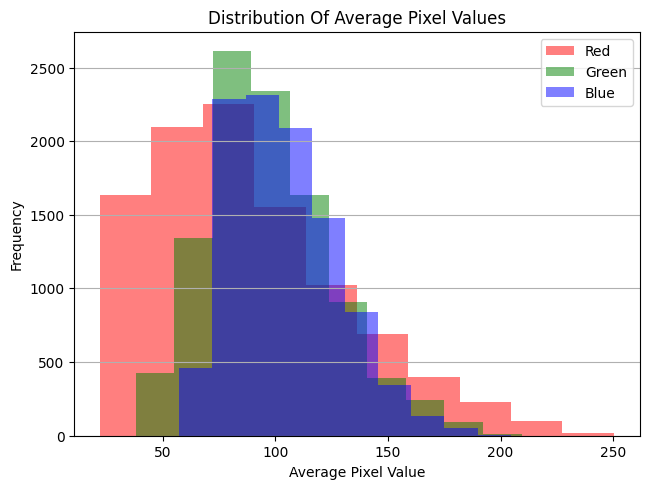

In [13]:
# your code goes here (average_pixel_plot)
def average_pixel_plot(df: pd.DataFrame) -> None:
    r_values = []
    g_values = []
    b_values = []

    for path in df['image_path']:
        img = mpimg.imread(path)
        r_values.append(img[:,:,0].mean())
        g_values.append(img[:,:,1].mean())
        b_values.append(img[:,:,2].mean())
    
    plt.hist(r_values, alpha=0.5, label='Red', color='red')
    plt.hist(g_values, alpha=0.5, label='Green', color='green')
    plt.hist(b_values, alpha=0.5, label='Blue', color='blue')
    plt.legend()
    plt.grid(axis='y')
    plt.title('Distribution Of Average Pixel Values')
    plt.tight_layout()
    plt.ylabel('Frequency')
    plt.xlabel('Average Pixel Value')
    plt.savefig(os.path.join(asset_path,"average_pixel_distribution.png"))

    plt.show()
        
    return 
average_pixel_plot(df)

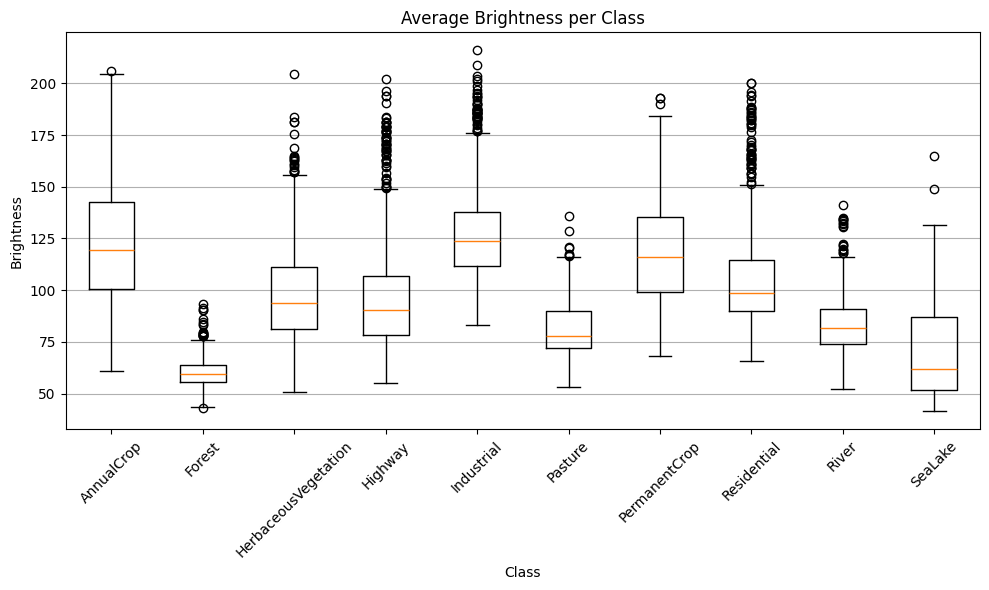

In [14]:
# your code goes here (average_brightness_per_class)
def average_brightness_per_class(df: pd.DataFrame) -> None:
    data = []
    for _class in range(len(classes)):
        t_df = df[df['label'] == _class]   
        brightness_values = []
        for path in t_df['image_path']:
            img = mpimg.imread(path)
            brightness_values.append(img.mean())
        data.append(brightness_values)
    #print(data)
    plt.figure(figsize=(10, 6))

    plt.boxplot(data, labels=classes)

    plt.title("Average Brightness per Class")
    plt.xlabel("Class")
    plt.ylabel("Brightness")

    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.grid(axis='y')
    plt.savefig(os.path.join(asset_path,"average_brightness.png"))

    plt.show()

    
average_brightness_per_class(df)

In [15]:
train_df = train_df.drop(columns=["image_folder"]) #not needed for training 
test_df = test_df.drop(columns=["image_folder"])
df = df.drop(columns=["image_folder"])

## CNN Implementation and Training

### Dataset class

In [16]:
from PIL import Image
from torch.utils.data import Dataset



from torchvision import transforms

transformer = transforms.Compose([
    
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(10),

    transforms.ToTensor(),
    transforms.Normalize([0.5, 0.5, 0.5],
                         [0.5, 0.5, 0.5])
])
test_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize([0.5, 0.5, 0.5],
                         [0.5, 0.5, 0.5])
]) #here we need to disable augmenation for results stability 



class ImageDataset(Dataset):
    def __init__(self, df, transformer):
        self.df = df
        self.transformer = transformer
        
    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]

        image = Image.open(row["image_path"]).convert("RGB")
        label = row["label"]

        image = self.transformer(image)

        return image, label


dataset = ImageDataset(train_df, transformer)
test_set = ImageDataset(test_df, test_transform)

#img, label = dataset.__getitem__(1)
#img

### Data Loaders

In [17]:
# your code goes here
from torch.utils.data import DataLoader

dataLoader = DataLoader(dataset= dataset, batch_size= 256, shuffle= True, num_workers= 0)
test_loader = DataLoader(dataset=test_set, batch_size= 256, shuffle= False, num_workers= 0 )  # i had a problem when raising the number of workers 

    

datatiter = iter(dataLoader)
data = next(datatiter)
#features , labels = data
#features.shape, labels.shape, len(classes) # needed info for model architecture 


### Model Architecture

In [18]:
import torch.nn as nn  
class CNN(nn.Module):
    def __init__(self, num_classes=10):
        super().__init__()

        self.features = nn.Sequential(

            nn.Conv2d(3, 32, kernel_size=3, stride=1, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),

            nn.Conv2d(32, 64, kernel_size=3, stride=2, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),

            nn.Conv2d(
                64,
                64,
                kernel_size=3,
                stride=1,
                padding=1,
                groups=64
            ),
            nn.Conv2d(64, 128, kernel_size=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),

            nn.Conv2d(
                128,
                128,
                kernel_size=3,
                stride=2,
                padding=1
            ),
            nn.BatchNorm2d(128),
            nn.ReLU(),
        )

        self.pool = nn.AdaptiveAvgPool2d((1, 1))
        self.flatten = nn.Flatten()
        self.dropout = nn.Dropout(0.5)
        self.classifier = nn.Linear(128, num_classes)

    def forward(self, x):
        x = self.features(x)
        x = self.pool(x)
        x = self.flatten(x)
        x = self.dropout(x)
        x = self.classifier(x)
        return x



In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

model =CNN(

    num_classes=10
).to(device)

loss_fn = nn.CrossEntropyLoss()

optimizer = optim.Adam(
    model.parameters(),
    lr=0.0001 # switched from 0.001 to 0.0001 after the first run for fine tunning  
)


In [20]:
print(device)

cuda


### Training Loop

In [ ]:
import copy
import os
import torch
import random
import numpy as np
#OPTIONS-----------
fine_tune = True
save_model = True
#-----------------




weights_path = os.path.join(asset_path, "weights.pth")

# FOR FINE TUNING THE MODEL

if os.path.exists(weights_path) and fine_tune:
    print("Loading saved weights...")
    model.load_state_dict(
        torch.load(weights_path, map_location=device)
    )
else:
    print("No saved weights found or fine tunning is disabled. Training from scratch.")

# REPRODUCIBILITY
seed = 42
random.seed(seed)
np.random.seed(seed)
torch.manual_seed(seed)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(seed)

epochs = 200
patience = 20

best_acc = 0
best_model = None
no_improve = 0

train_losses_plot = []
test_losses_plot = []
acc_plot = []

# TRAINING LOOP
for epoch in range(epochs):

   
    # TRAIN
   
    model.train()

    train_losses = []

    for images, labels in dataLoader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = loss_fn(outputs, labels)

        loss.backward()
        optimizer.step()

        train_losses.append(loss.item())

    train_loss = sum(train_losses) / len(train_losses)

    # EVALUATION
    model.eval()
    test_losses = []
    correct = 0
    total = 0

    with torch.inference_mode():
        for images, labels in test_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = loss_fn(outputs, labels)

            test_losses.append(loss.item())

            predicted = torch.argmax(outputs, dim=1)

            correct += (predicted == labels).sum().item()
            total += labels.size(0)

    test_loss = sum(test_losses) / len(test_losses)
    accuracy = (correct / total) * 100

    # SAVE METRICS
    train_losses_plot.append(train_loss)
    test_losses_plot.append(test_loss)
    acc_plot.append(accuracy)


    # SAVING THE BEST MODEL (tried to copy without copy.deepcopy it was picking up random models)
   
    if accuracy > best_acc:
        best_acc = accuracy
        best_model = copy.deepcopy(model.state_dict())
        no_improve = 0
    else:
        no_improve += 1

    
    # EARLY STOPPING
    
    if no_improve >= patience:
        print("Early stopping")
        break

    
    # LOGGING
    
    print(f"Epoch: {epoch + 1}")
    print(f"Train Loss: {train_loss:.4f}")
    print(f"Test Loss: {test_loss:.4f}")
    print(f"Accuracy: {accuracy:.2f}%")
    print(f"Best Accuracy: {best_acc:.2f}%")
    print("___________________________________________")


# SAVE BEST MODEL

if best_model is not None and save_model:
    torch.save(best_model, weights_path)
    print(f"Best model saved to: {weights_path}")

Loading saved weights...
Epoch: 1
Train Loss: 0.0485
Test Loss: 0.0952
Accuracy: 97.00%
Best Accuracy: 97.00%
___________________________________________
Epoch: 2
Train Loss: 0.0523
Test Loss: 0.0938
Accuracy: 97.05%
Best Accuracy: 97.05%
___________________________________________
Epoch: 3
Train Loss: 0.0500
Test Loss: 0.0981
Accuracy: 96.90%
Best Accuracy: 97.05%
___________________________________________
Epoch: 4
Train Loss: 0.0492
Test Loss: 0.0971
Accuracy: 96.80%
Best Accuracy: 97.05%
___________________________________________
Epoch: 5
Train Loss: 0.0530
Test Loss: 0.0966
Accuracy: 96.70%
Best Accuracy: 97.05%
___________________________________________
Epoch: 6
Train Loss: 0.0563
Test Loss: 0.0994
Accuracy: 96.85%
Best Accuracy: 97.05%
___________________________________________
Epoch: 7
Train Loss: 0.0512
Test Loss: 0.0982
Accuracy: 96.90%
Best Accuracy: 97.05%
___________________________________________
Epoch: 8
Train Loss: 0.0535
Test Loss: 0.1014
Accuracy: 96.90%
Best Accu

## Model Evaluation

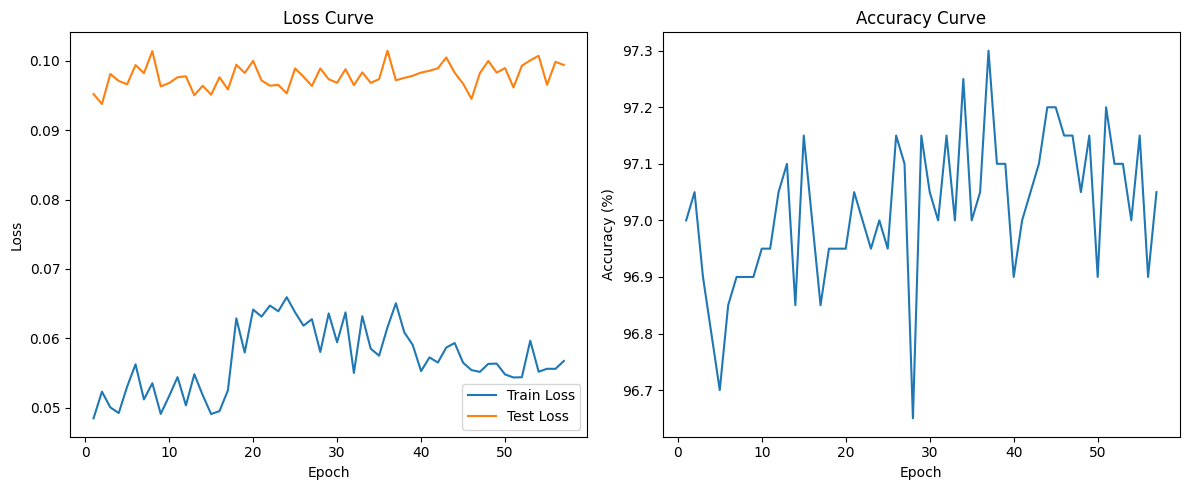

In [34]:
import matplotlib.pyplot as plt

epochs_ran = range(1, len(train_losses_plot) + 1)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))


# Loss plot

axes[0].plot(epochs_ran, train_losses_plot, label="Train Loss")
axes[0].plot(epochs_ran, test_losses_plot, label="Test Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].set_title("Loss Curve")
axes[0].legend()

# Accuracy plot

axes[1].plot(epochs_ran, acc_plot)
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy (%)")
axes[1].set_title("Accuracy Curve")

plt.tight_layout()
plt.show()

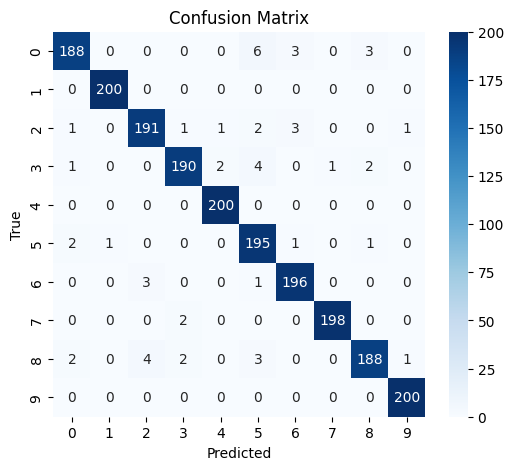

In [35]:
#https://stackoverflow.com/questions/35572000/how-can-i-plot-a-confusion-matrix 
#USED ONLY AS A REFERENCE 
model.load_state_dict(torch.load(os.path.join(asset_path,'weights.pth'), map_location=device)
                      )
import torch
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

y_true = []
y_pred = []

model.eval()

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)

        outputs = model(images)
        preds = torch.argmax(outputs, dim=1)

        y_pred.extend(preds.cpu().tolist())
        y_true.extend(labels.tolist())

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Confusion Matrix")
plt.show()

In [ ]:
# your code goes here (plot_misclassified_samples)


### Test Set

In [36]:
# your code goes here (preprocess_test_data)

def preprocess(img_folder:str):
    row = []
    for img in os.listdir(img_folder):
        row.append({'folder' : img_folder
                    ,
                    'file_name': img})
    
    df = pd.DataFrame(row)
    return df
df = preprocess('test_data')
#df


In [37]:
df['label'] = -1  # placeholder label

df["image_path"] = [
    os.path.join(folder, file_name)
    for folder, file_name in zip(df["folder"], df["file_name"])
] #path needed to get our data through the dataset  class 

test2_set = ImageDataset(df, test_transform)

d_loader = DataLoader(
    test2_set,
    batch_size=64,
    shuffle=False
)

In [38]:
# your code goes here (evaluate model on test set)

model.load_state_dict(
    torch.load(os.path.join(asset_path, "weights.pth"), map_location=device)
)

model.eval()

all_preds = []

with torch.inference_mode():
    for images, _ in d_loader:  # ignoring labels
        images = images.to(device)

        outputs = model(images)

        preds = outputs.argmax(dim=1)

        all_preds.extend(
            preds.cpu().tolist()
        )

act_prob = [rev_classes[p] for p in all_preds]

In [39]:
# your code goes here (create submission csv file for challenge server)
df['label'] = act_prob

df = df.drop(columns=[ 'folder','image_path'])
df.to_csv(
    "submission.csv",
    index=False,
    header=False
)